# 06 — Research report and offline player comparison

Build the written report, five static figures, and a self-contained local HTML companion from the current saved outputs. The companion selects Combine position, exact official time, players, and attempts, and shows speed, signed acceleration, observed peaks, speed-band intervals, and a recorded-time cursor. Cross-position mode is optional.

This is a **research draft**: all-position NFL linkage, physical-unit verification, and final public-Kaggle-notebook packaging remain incomplete. The previous 43-WR result is presented as a limited pilot, not a verdict on all positions or peak timing. The HTML companion does not replace the required competition writeup/public notebook.

Run Notebooks 02, 03, and 05 first. This notebook reads saved results; it does not scan the large NFL tracking files, refit models, use API tokens, publish a site, or send data to an external service.


## A. Load the reproducible report builder

The narrative source is `report/templates/writeup.md`; styles and interaction source are in `report/assets/`. The builder checks source hashes and fixed draft facts rather than silently retaining a stale narrative after the data changes. All interaction code and figure images are embedded in the generated HTML so the report can be opened offline.


In [1]:
from pathlib import Path
import importlib
import json
import sys
from IPython.display import display,Image

ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents]
           if (p/"scripts/build_report.py").is_file()),None)

if ROOT is None:
    raise FileNotFoundError("Open the project or notebooks folder")

if str(ROOT/"scripts") not in sys.path:
    sys.path.insert(0,str(ROOT/"scripts"))

import build_report

importlib.reload(build_report)
print("Report folder:",ROOT/"report")

Report folder: /Users/hunterclark/Documents/New project/nfl-big-data-bowl-2027/report


## B. Build the report and companion

The written draft stays within 2,000 words and our working eight-visual budget. The current draft uses five figures and one cohort table. Interactive player comparisons are supplementary; they are not a way to bypass the submission content rules. No finish-line race or reconstructed physical launch is invented.


In [2]:
report_result=build_report.build_report(ROOT)

print("Written draft:",report_result["markdown_word_count"],"words")
print("Static visuals:",report_result["figures"],"figures +",report_result["tables"],"table")
print("Offline comparison:",report_result["players"],"players;",report_result["recordings"],"recordings")
print("HTML report:",ROOT/"report/index.html")
print("Markdown writeup:",ROOT/"report/writeup.md")
print("Status:",report_result["status"])

Written draft: 1426 words
Static visuals: 5 figures + 1 table
Offline comparison: 418 players; 793 recordings
HTML report: /Users/hunterclark/Documents/New project/nfl-big-data-bowl-2027/report/index.html
Markdown writeup: /Users/hunterclark/Documents/New project/nfl-big-data-bowl-2027/report/writeup.md
Status: Research draft; all-position NFL linkage and physical-unit checks incomplete


## C. Review static evidence

The illustrative exact-time group is chosen using Combine metadata alone: the largest same-year WR group sharing a published time, with ties resolved by year and official time. It is not chosen by NFL outcomes or maximum separation between curves. Keep boundary peaks visible and preserve the uncertainty and the unfavorable NFL pilot result.


01_same_time_profiles.png


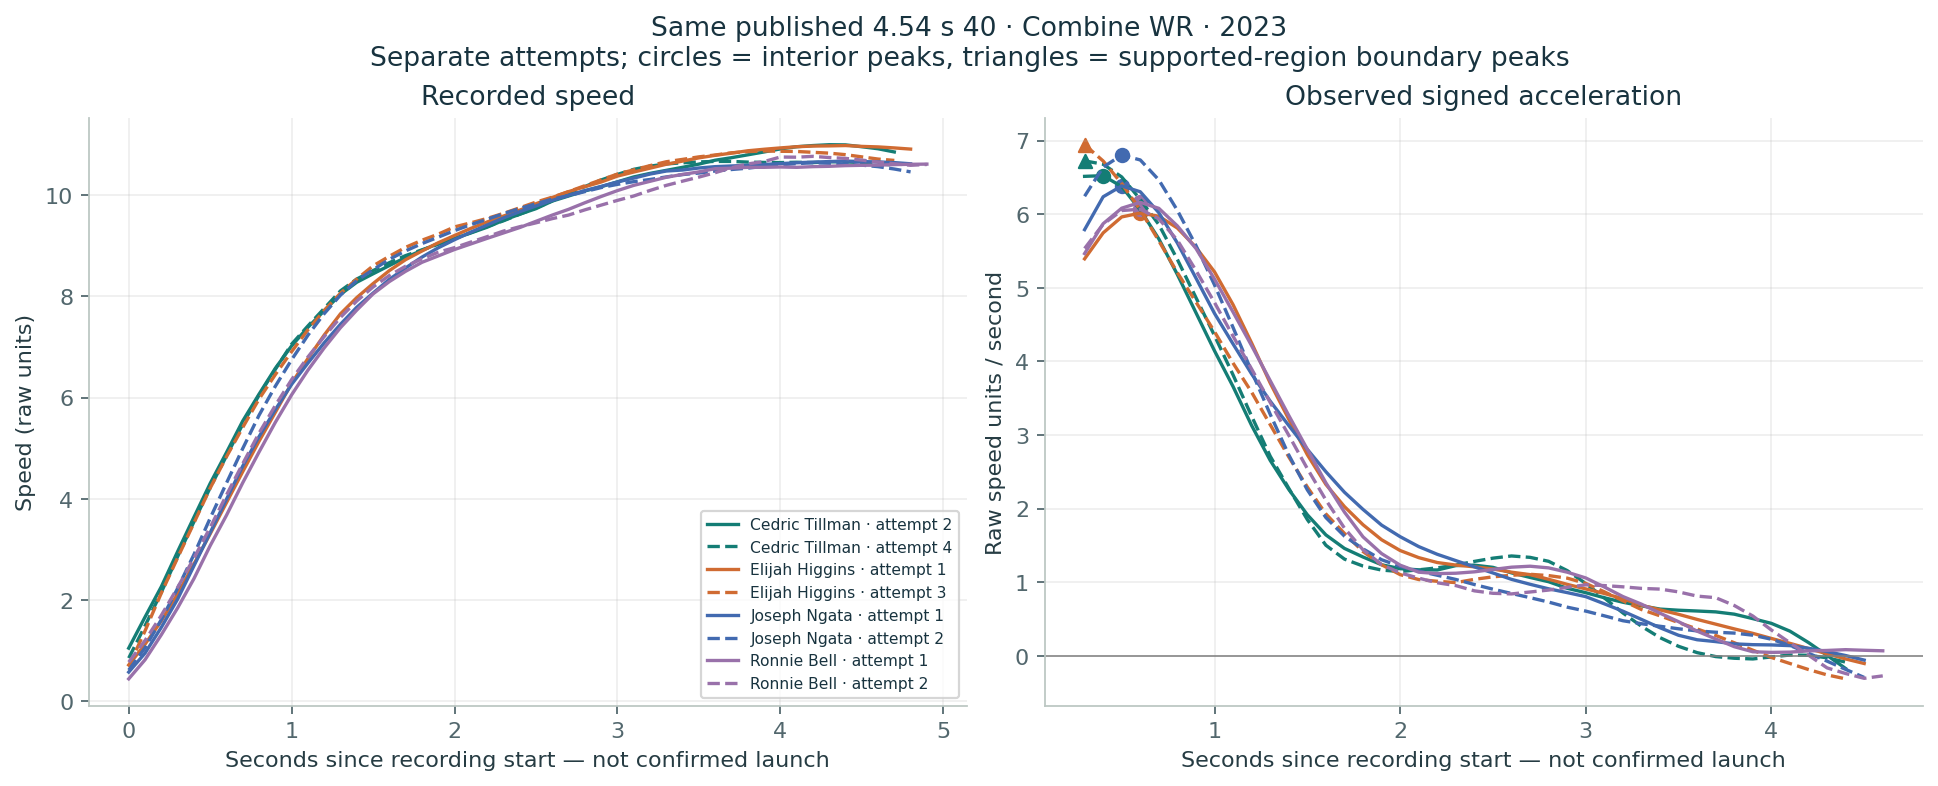

02_speed_band_coverage.png


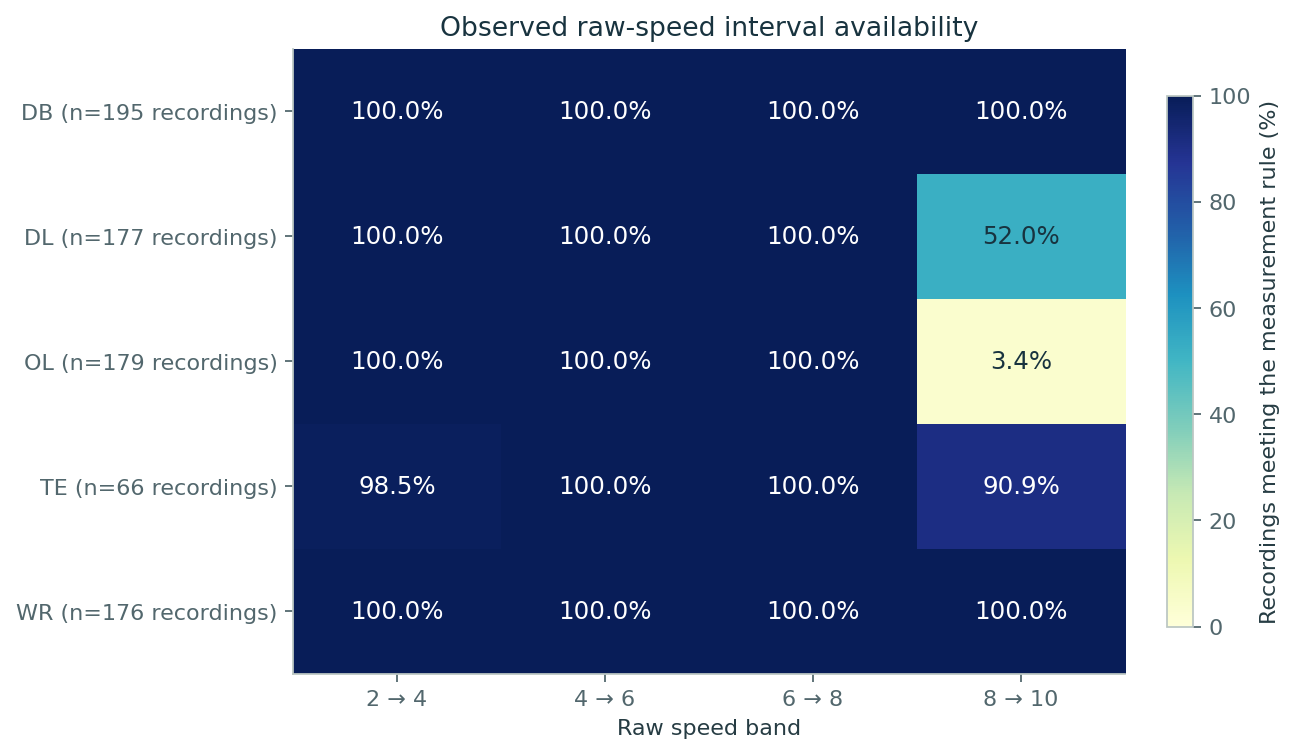

03_peak_repeatability.png


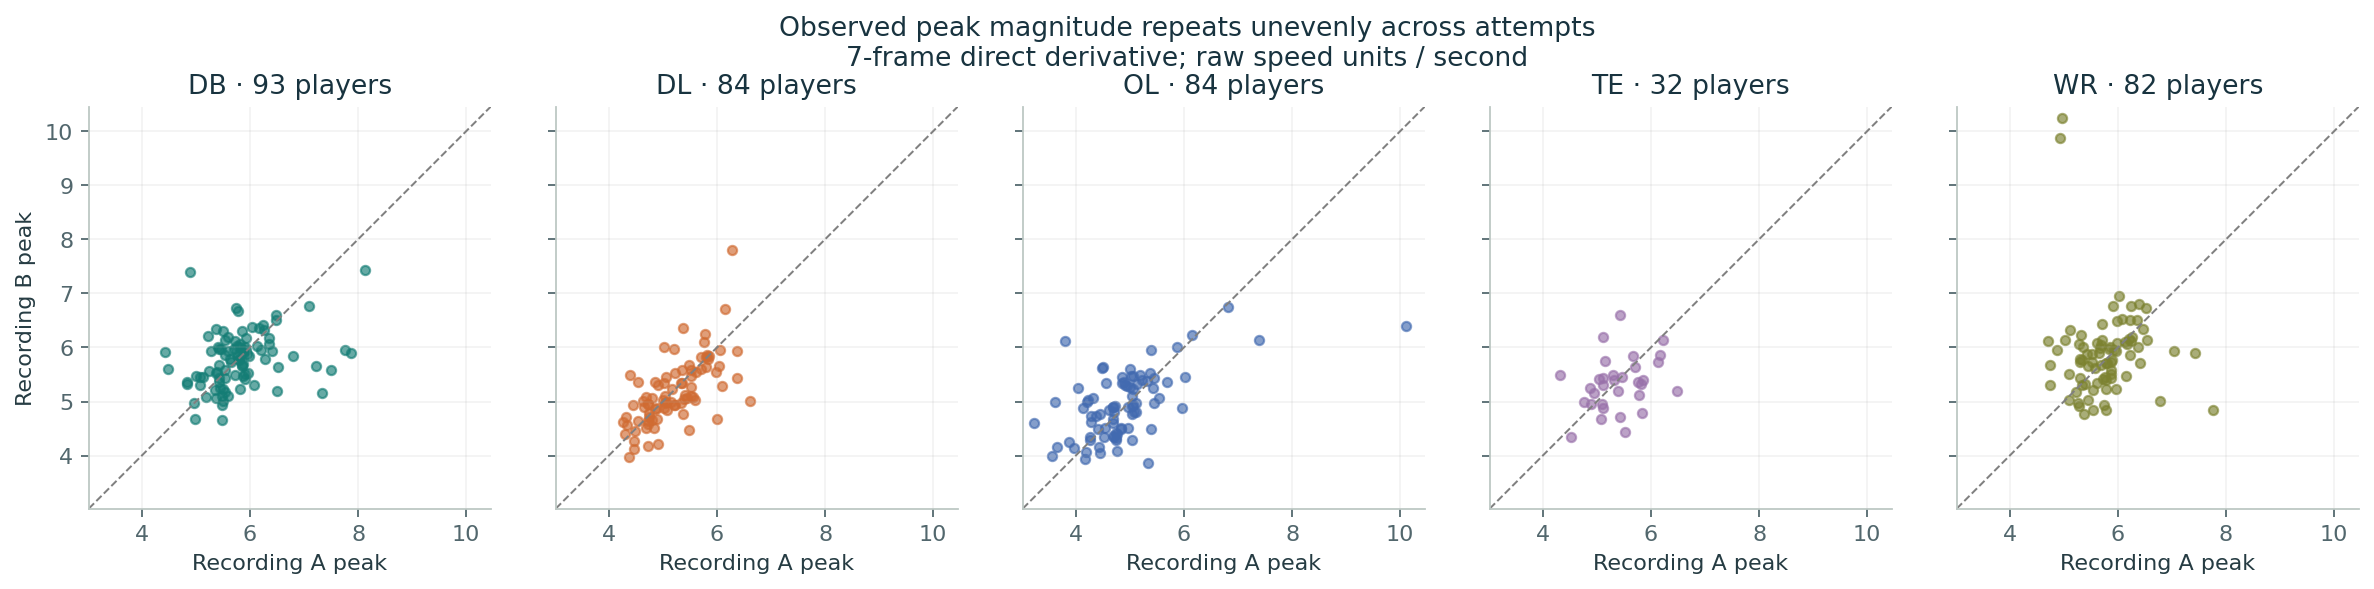

04_timing_agreement.png


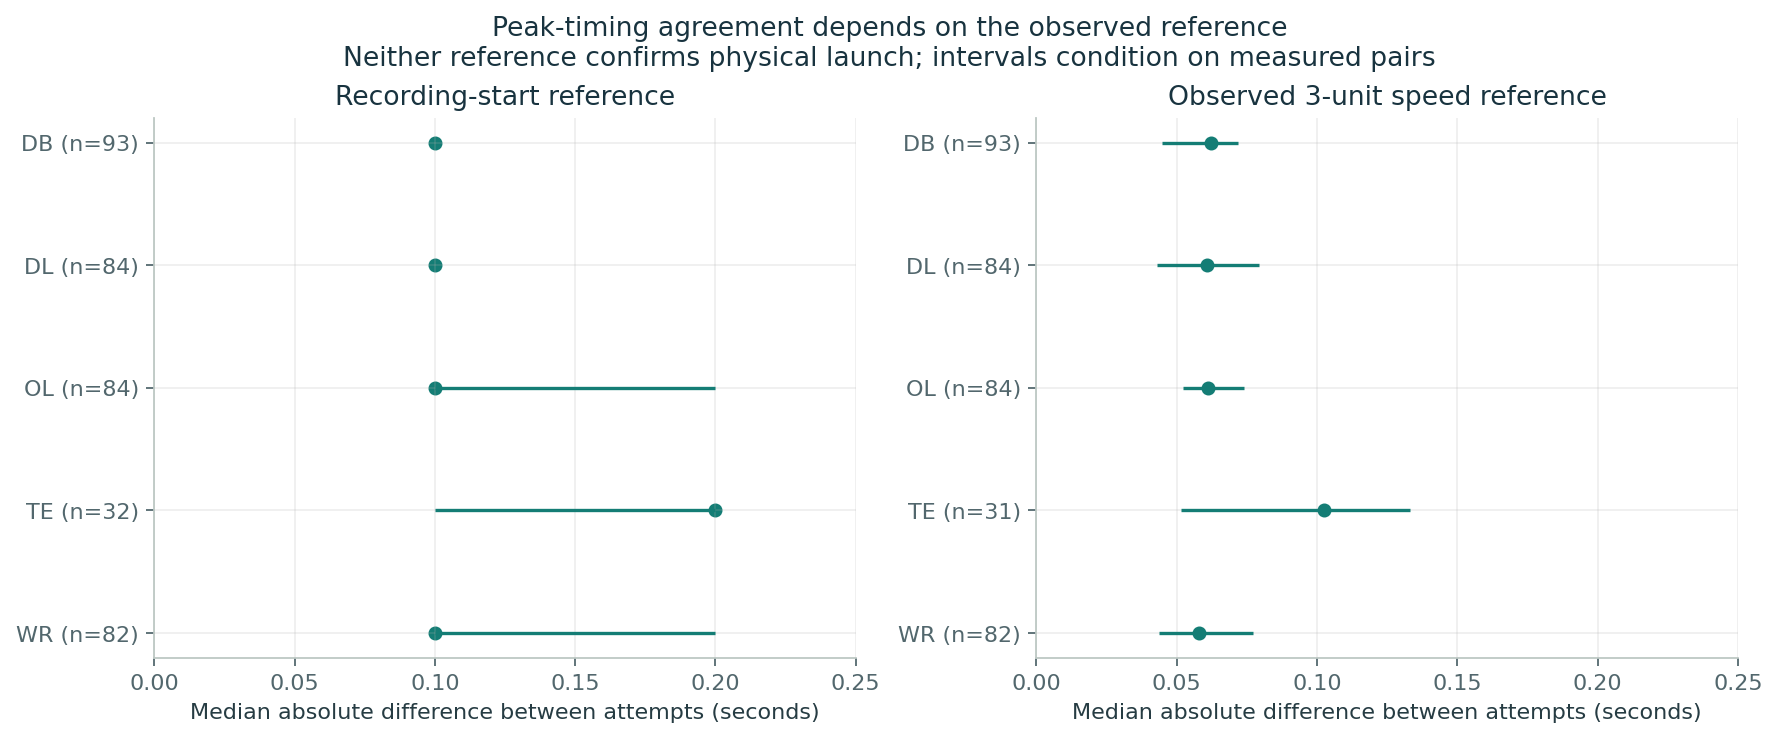

05_wr_pilot_result.png


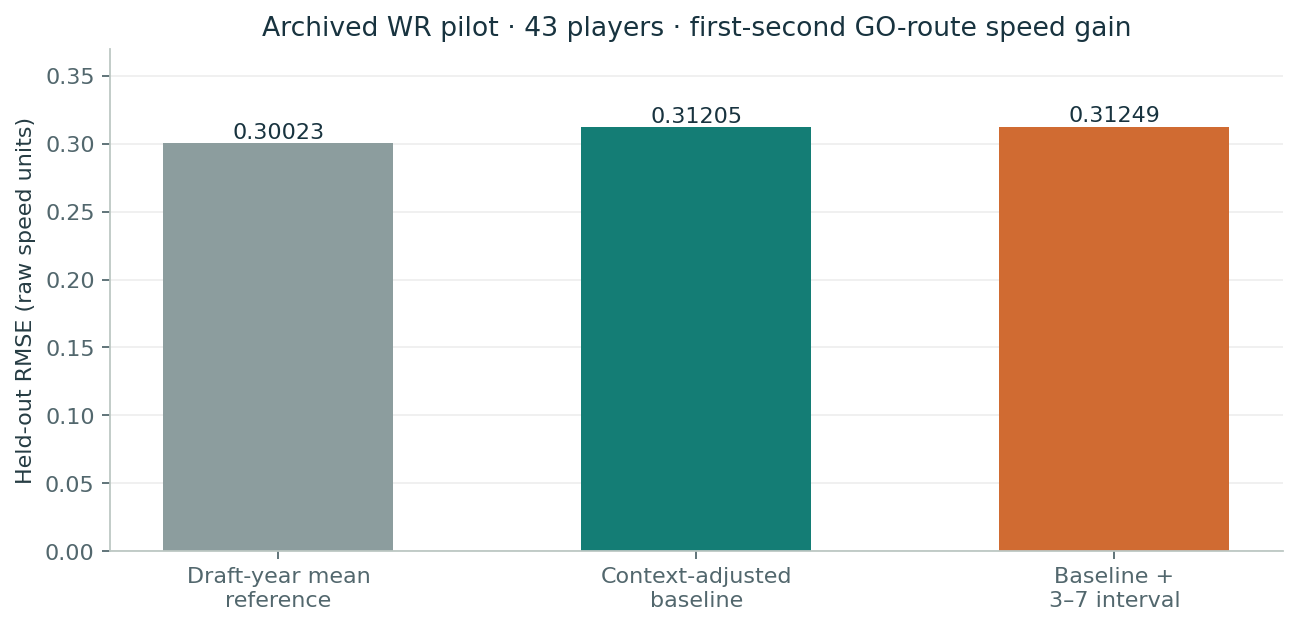

In [3]:
for path in sorted((ROOT/"report/figures").glob("*.png")):
    print(path.name)
    display(Image(filename=str(path),width=1000))


## D. Open and inspect the companion

Open `report/index.html` in a browser. Use **Player comparison**, then position → exact official time → players → attempts. Change draft year, smoothing, or the observed timing reference. The cursor replays observed time on the plots; it does not claim the selected recordings start at physical launch or represent the same officially timed attempt.

The original 43-WR model remains in the archive and is marked as a pilot. The new all-position NFL stage has not been run. Before calling the writeup submission-ready, resolve the remaining measurement definitions, complete the intended NFL linkage, and package and run a public Kaggle notebook.
